# Régression multivariée (Prédiction du prix) 

In [1]:
%pip install openpyxl statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.3 MB 762.0 kB/s eta 0:00:15
   -- ------------------------------------- 0.8/11.3 MB 907.1 kB/s eta 0:00:12
   --- ------------------------------------ 1.0/11.3 MB 1.1 MB/s eta 0:00:10
   ---- ----------------------------------- 1.3/11.3 MB 1.1 MB/s eta 0:00:09
   ----- ---------------------------------- 1.6/11.3 MB 1.1 MB/s eta 0:00:09
   ------ --------------------------------- 1.8/11.3 MB 1.1 MB/s eta 0:00:09
   ------- -------------------------------- 2.1/11.3 MB 1.1 MB/s eta 0:00:09
   ---------- ----------------------------- 2.9/11.3 MB 1.4 MB/s eta 0:00:07
   ------------ --------------------------- 3.4/11.3 MB 1.5 MB/s eta 0:00:06
   -------------- -----


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from dotenv import load_dotenv

load_dotenv()
DATA_DIR = os.getenv("DATA_DIR")

df = pd.read_excel(os.path.join(DATA_DIR, "MultivariateLinearRegression.xlsx"))
print(len(df))
print(df.head())
print(df.describe())

Y = df["prix"]                                        # variable cible
X = df[['taille_en_pieds_carre', 'nb_chambres']]      # variables prédictives

47
   taille_en_pieds_carre  nb_chambres    prix
0                   2104            3  399900
1                   1600            3  329900
2                   2400            3  369000
3                   1416            2  232000
4                   3000            4  539900
       taille_en_pieds_carre  nb_chambres           prix
count              47.000000    47.000000      47.000000
mean             2000.680851     3.170213  340412.659574
std               794.702354     0.760982  125039.899586
min               852.000000     1.000000  169900.000000
25%              1432.000000     3.000000  249900.000000
50%              1888.000000     3.000000  299900.000000
75%              2269.000000     4.000000  384450.000000
max              4478.000000     5.000000  699900.000000


### Q4) Visualisation des données (nuage de points 3D)

Le nuage représente le prix de vente en fonction de la superficie (pieds²) et du nombre de chambres, pour 47 maisons.

**Interprétation :**
- **Tendance croissante** : le prix augmente avec la superficie et, dans une moindre mesure, avec le nombre de chambres.
- **Forme approximativement plane** : les points s'organisent autour d'un plan incliné, ce qui justifie un modèle de **régression linéaire multivariée** $\text{prix} = \varepsilon + \alpha \cdot \text{superficie} + \beta \cdot \text{chambres}$.
- **La superficie est la variable la plus déterminante** : à nombre de chambres égal, le prix varie fortement avec la superficie.
- **Variables prédictives corrélées** : les grandes maisons ont généralement plus de chambres ; les deux variables apportent donc en partie la même information (colinéarité).
- **Concentration des données** : la majorité des maisons ont entre 1 000 et 2 500 pieds² et 3 chambres, avec des prix entre 200 000 et 400 000. Quelques grandes maisons (> 4 000 pieds², 4–5 chambres, jusqu'à ≈ 700 000) sont rares et isolées.
- **Ordres de grandeur très différents** : la superficie se compte en milliers alors que le nombre de chambres varie de 1 à 5, d'où la nécessité d'une **mise à l'échelle** (StandardScaler) avant d'appliquer l'algorithme.

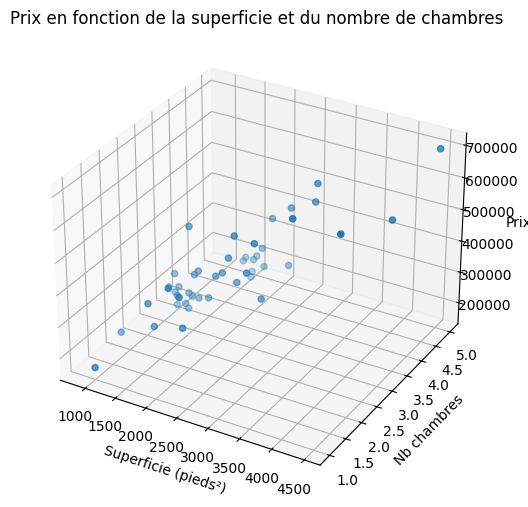

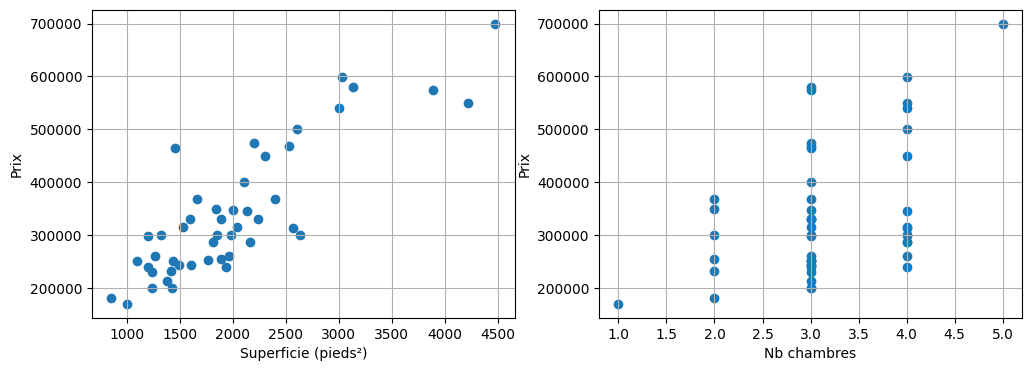

In [3]:
# Nuage 3D
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X['taille_en_pieds_carre'], X['nb_chambres'], Y, c='tab:blue')
ax.set_xlabel('Superficie (pieds²)')
ax.set_ylabel('Nb chambres')
ax.set_zlabel('Prix')
ax.set_title('Prix en fonction de la superficie et du nombre de chambres')
plt.show()

# Nuages 2D : chaque variable séparément
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(X['taille_en_pieds_carre'], Y)
axes[0].set_xlabel('Superficie (pieds²)'); axes[0].set_ylabel('Prix'); axes[0].grid(True)
axes[1].scatter(X['nb_chambres'], Y)
axes[1].set_xlabel('Nb chambres'); axes[1].set_ylabel('Prix'); axes[1].grid(True)
plt.show()

### Mise à l'échelle (feature scaling)

Les variables prédictives ont des ordres de grandeur très différents (superficie ≈ 1 000–4 500, chambres ≈ 1–5). On applique une **standardisation** à chaque variable :
$$x' = \frac{x - \mu}{\sigma}$$
Après transformation, chaque variable a une moyenne de 0 et un écart-type de 1 (valeurs ≈ entre −2 et 2) : elles deviennent comparables.

**Remarque :** `.as_matrix()` de l'énoncé n'existe plus dans pandas ; il est remplacé par `.values`.

In [4]:
scale = StandardScaler()
X_scaled = scale.fit_transform(X[['taille_en_pieds_carre', 'nb_chambres']].values)
print(X_scaled[:5])

[[ 0.13141542 -0.22609337]
 [-0.5096407  -0.22609337]
 [ 0.5079087  -0.22609337]
 [-0.74367706 -1.5543919 ]
 [ 1.27107075  1.10220517]]


### Régression multivariée (OLS) — Résultats

OLS minimise la somme des carrés des écarts entre prix observés et prédits :
$$\min_{\alpha,\beta} \sum_{i=1}^{n} \big(y_i - (\alpha \cdot \text{superficie}_i + \beta \cdot \text{chambres}_i)\big)^2$$

| Variable | Coefficient | p-value | IC à 95 % |
|---|---|---|---|
| superficie | α = 140,86 | < 0,001 | [109,9 ; 171,8] |
| nb_chambres | β ≈ 16 980 | 0,101 | [−3 425 ; 37 400] |

Modèle : $\text{prix} \approx 140{,}86 \times \text{superficie} + 16\,980 \times \text{chambres}$

**Prédiction** (4 500 pieds², 5 chambres) : **≈ 718 766**.

**Interprétation :**
- **Superficie** : très significative (p < 0,001) ; chaque pied² supplémentaire ajoute ≈ 141 au prix.
- **Nombre de chambres** : **non significatif** au seuil de 5 % (p = 0,101, l'intervalle de confiance contient 0). À superficie connue, le nombre de chambres n'apporte pas d'information fiable supplémentaire.
- **Multicollinéarité** (Cond. No. = 2 170) : superficie et nombre de chambres sont corrélés (les grandes maisons ont plus de chambres), ce qui rend le coefficient β instable.
- **Résidus** : Jarque-Bera (p = 0,545) → résidus compatibles avec une loi normale ; Durbin-Watson ≈ 1,92 → pas d'autocorrélation. Les hypothèses du modèle sont respectées.

**Remarques critiques :**
- `sm.OLS(Y, X)` **sans constante** : le plan passe par l'origine, alors que le modèle théorique contient ε. Le $R^2$ affiché (0,966) est **non centré** et donc artificiellement élevé.
- La régression utilise `X` et non `X_scaled` : la mise à l'échelle n'est pas exploitée. Pour OLS (solution exacte), cela ne change pas les prédictions, seulement l'échelle des coefficients ; le scaling est indispensable surtout pour la **descente de gradient**.

In [5]:
model = sm.OLS(Y, X).fit()
print(model.summary())

def predict_price_of_house(taille_maison, nb_chambre):
    return model.params['taille_en_pieds_carre'] * taille_maison + model.params['nb_chambres'] * nb_chambre

print(predict_price_of_house(4500, 5))

                                 OLS Regression Results                                
Dep. Variable:                   prix   R-squared (uncentered):                   0.966
Model:                            OLS   Adj. R-squared (uncentered):              0.964
Method:                 Least Squares   F-statistic:                              631.4
Date:                Wed, 18 Nov 2026   Prob (F-statistic):                    1.19e-33
Time:                        16:21:09   Log-Likelihood:                         -589.11
No. Observations:                  47   AIC:                                      1182.
Df Residuals:                      45   BIC:                                      1186.
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
                            coef    std err          t      P>|t|      [0.025      0.975]
------------------------------